## DataCo Smart Supply Chain — Late Delivery Risk Prediction



## 1. Business Framing (Athauda P.A.K.D.)

**Business problem:** A logistics company wants to improve delivery reliability and reduce operational
delays. Late deliveries reduce customer satisfaction and increase operational cost, so the company
needs a way to flag orders that are likely to arrive late.

**Stakeholder:** Logistics/operations planning team.

**Decision need:** Given the information known when an order is placed (customer, product, market,
shipping mode chosen, order value, etc.), decide whether the order is at risk of a late delivery so
that operations staff can prioritise it.

**Unit of analysis:** One order/shipment record.

**Primary decision lens:** Late delivery risk.

**Secondary decision lens:** Delay pattern analysis — used only to explain *why* certain orders are
flagged as high risk (which markets, shipping modes and categories are associated with delay), which
supports the interpretation of the primary lens.

**ML task:** Binary classification — predict `Late_delivery_risk` (1 = late, 0 = not late).

**Target variable:** `Late_delivery_risk` 



## 2. Data Understanding & EDA

### 2.1 Import libraries and load the dataset


In [1]:
# Basic libraries for data handling and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries used later in the notebook
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, RocCurveDisplay)

# Keep plots looking consistent
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

# Reproducibility
RANDOM_STATE = 42


In [ ]:
# Load the dataset
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='latin1')

print('Shape of dataset:', df.shape)
df.head()


Shape of dataset: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
# Basic structure of the dataset: column names and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [4]:
# Summary statistics for the numeric columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


### 2.2 Data quality checks — missing values and duplicates

In [5]:
# Check how many missing values each column has
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print('Columns with missing values:')
print(missing)


Columns with missing values:
Product Description    180519
Order Zipcode          155679
Customer Lname              8
Customer Zipcode            3
dtype: int64


In [6]:
# Check for fully duplicated rows
print('Number of duplicate rows:', df.duplicated().sum())


Number of duplicate rows: 0


**Data quality observations (EDA Insight Log):**

| Issue found | Detail | Decision |
|---|---|---|
| `Product Description` | 100% missing | Drop column — carries no information |
| `Order Zipcode` | ~86% missing | Drop column — too sparse to use reliably |
| `Customer Lname`, `Customer Zipcode` | A handful of missing values | Not used as model features (identifier/PII), no action needed |
| Duplicate rows | None found | No rows removed |
| `Delivery Status` | Perfectly matches `Late_delivery_risk` (it is just the target renamed) | Must be dropped, otherwise the model would "cheat" |
| `Days for shipping (real)` | Directly used to compute `Late_delivery_risk`, so it is only known *after* the shipment has already happened | Must be dropped — using it would be data leakage |
| `shipping date (DateOrders)` | Only known after shipment, closely tied to the leaking columns above | Must be dropped |


### 2.3 Target variable distribution

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64
Late_delivery_risk
1    54.83
0    45.17
Name: count, dtype: float64


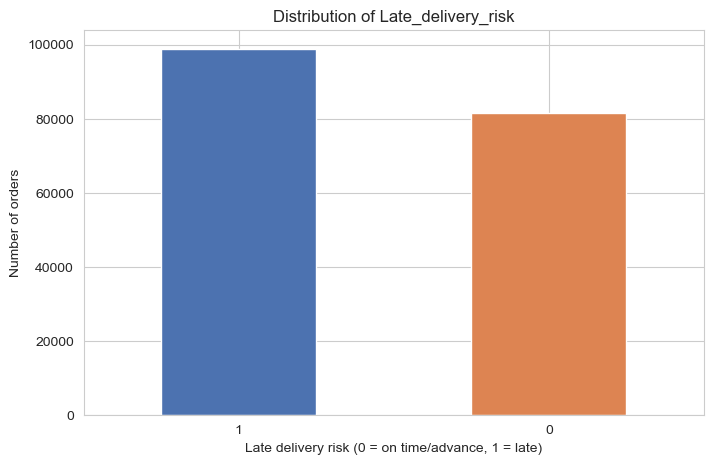

In [7]:
# Look at how balanced the target classes are
target_counts = df['Late_delivery_risk'].value_counts()
print(target_counts)
print((target_counts / len(df) * 100).round(2))

target_counts.plot(kind='bar', color=['#4C72B0', '#DD8452'])
plt.title('Distribution of Late_delivery_risk')
plt.xlabel('Late delivery risk (0 = on time/advance, 1 = late)')
plt.ylabel('Number of orders')
plt.xticks(rotation=0)
plt.show()


### 2.4 Late delivery risk by shipping mode

Shipping Mode
First Class       0.953225
Second Class      0.766328
Same Day          0.457430
Standard Class    0.380717
Name: Late_delivery_risk, dtype: float64


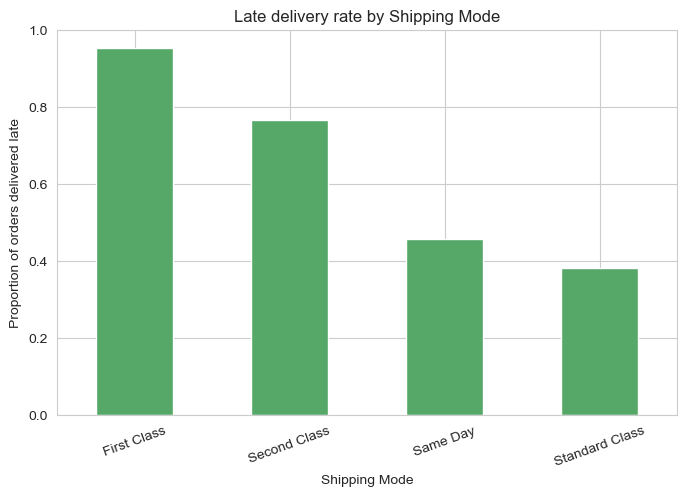

In [8]:
# Shipping Mode is chosen by the customer/company at order time, so it is a
# legitimate feature (not leakage) even though it is a very strong signal
ship_rate = df.groupby('Shipping Mode')['Late_delivery_risk'].mean().sort_values(ascending=False)
print(ship_rate)

ship_rate.plot(kind='bar', color='#55A868')
plt.title('Late delivery rate by Shipping Mode')
plt.ylabel('Proportion of orders delivered late')
plt.xticks(rotation=20)
plt.show()


### 2.5 Late delivery risk by market and product category (delay pattern analysis)

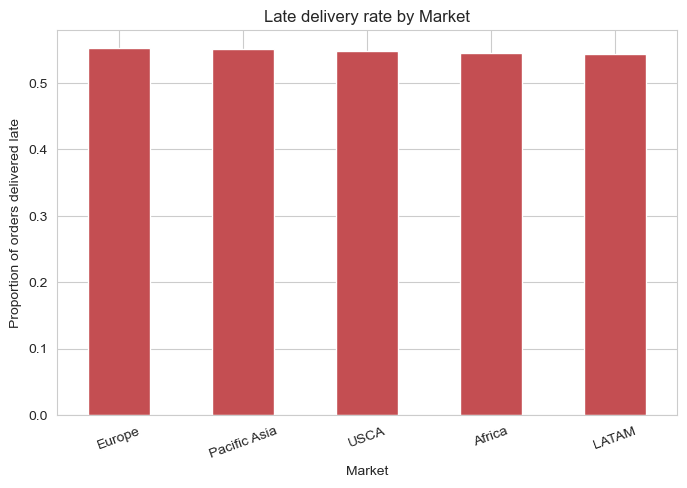

In [9]:
# Secondary lens: look at which markets tend to have more delays
market_rate = df.groupby('Market')['Late_delivery_risk'].mean().sort_values(ascending=False)
market_rate.plot(kind='bar', color='#C44E52')
plt.title('Late delivery rate by Market')
plt.ylabel('Proportion of orders delivered late')
plt.xticks(rotation=20)
plt.show()


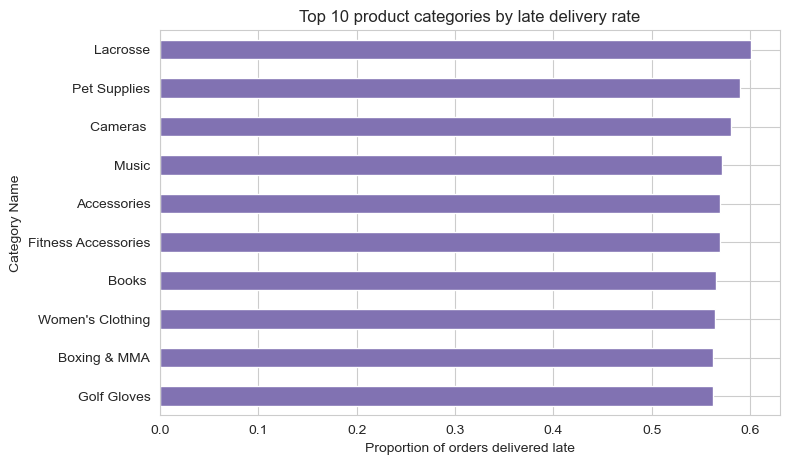

In [10]:
# Top 10 product categories with the highest late delivery rate (minimum 200 orders,
# so the rate is not based on just a handful of orders)
cat_counts = df['Category Name'].value_counts()
valid_cats = cat_counts[cat_counts >= 200].index
cat_rate = df[df['Category Name'].isin(valid_cats)].groupby('Category Name')['Late_delivery_risk'].mean()
cat_rate.sort_values(ascending=False).head(10).plot(kind='barh', color='#8172B2')
plt.title('Top 10 product categories by late delivery rate')
plt.xlabel('Proportion of orders delivered late')
plt.gca().invert_yaxis()
plt.show()


### 2.6 Correlation between numeric features

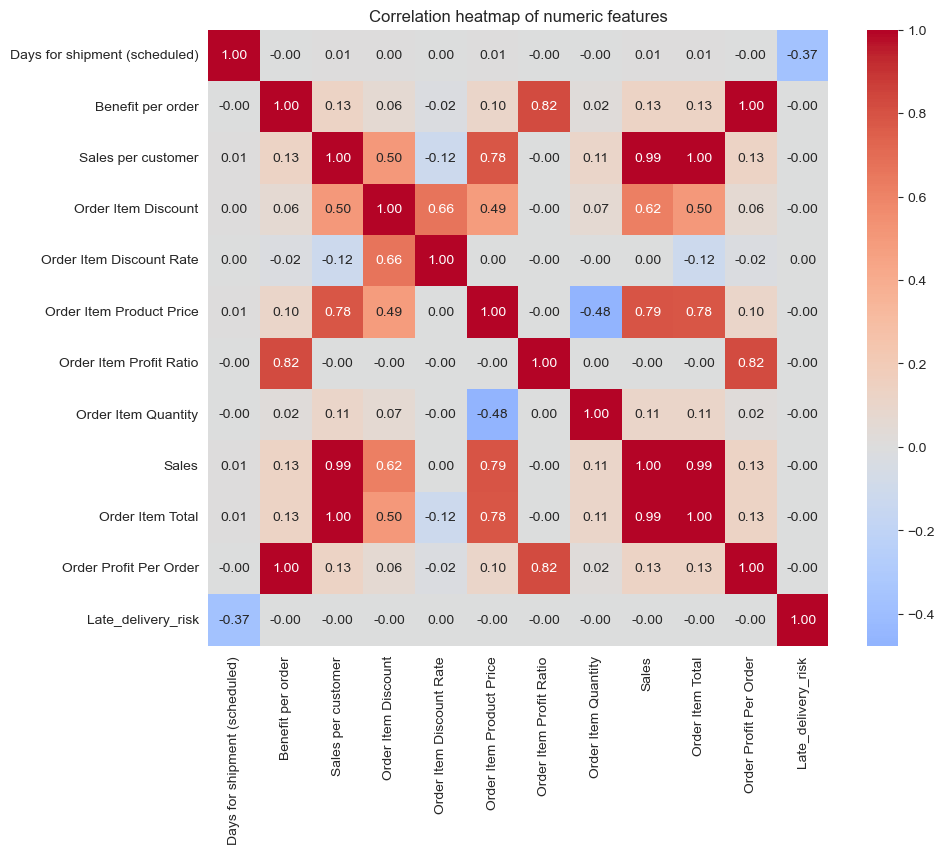

In [11]:
# Correlation heatmap for the main numeric columns (helps spot redundant features)
numeric_cols = ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer',
                'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price',
                'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total',
                'Order Profit Per Order', 'Late_delivery_risk']

plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap of numeric features')
plt.show()


**EDA summary:**
`Days for shipment (scheduled)` and `Shipping Mode` describe the same thing (each shipping mode
always has a fixed scheduled number of days) and are the strongest single predictors of late
delivery. Market, order region and product category show smaller but real differences in delay
rate, which supports keeping geography and category information as model features. Most of the
sales/profit numeric columns are only weakly correlated with the target on their own but may still
help models when combined with other features.



## 3. Data Preprocessing (Pamindi M.M.)


In [12]:
# Work on a copy so the original dataframe stays untouched
data = df.copy()

# --- Columns that leak the answer or are only known after delivery has happened ---
leakage_cols = ['Delivery Status', 'Days for shipping (real)', 'shipping date (DateOrders)']

# --- Personally identifiable / free-text columns that should not be used as features ---
pii_cols = ['Customer Email', 'Customer Password', 'Customer Fname', 'Customer Lname',
            'Customer Street', 'Product Description', 'Product Image', 'Order Zipcode',
            'Customer Zipcode']

# --- ID columns that are just row/record identifiers, not real predictive features ---
id_cols = ['Order Id', 'Order Item Id', 'Order Customer Id', 'Customer Id', 'Product Card Id',
           'Order Item Cardprod Id', 'Category Id', 'Department Id', 'Product Category Id',
           'Product Status']

drop_cols = leakage_cols + pii_cols + id_cols
data = data.drop(columns=[c for c in drop_cols if c in data.columns])

print('Remaining columns after dropping leakage/PII/ID columns:', data.shape[1])


Remaining columns after dropping leakage/PII/ID columns: 31


In [13]:
# Convert the order date into a proper datetime and pull out useful parts of it
# (the exact timestamp is not useful on its own, but month/day-of-week patterns can be)
data['order date (DateOrders)'] = pd.to_datetime(data['order date (DateOrders)'])
data['order_month'] = data['order date (DateOrders)'].dt.month
data['order_dayofweek'] = data['order date (DateOrders)'].dt.dayofweek

# The raw timestamp column can now be dropped, its useful parts are extracted above
data = data.drop(columns=['order date (DateOrders)'])


In [14]:
# Double check there are no missing values left in the columns we plan to use
data.isnull().sum().sum()


0

In [15]:
# Confirm there are no duplicate rows in the cleaned dataset
data.duplicated().sum()


0

**Preprocessing log:**

| Step | Action | Reason |
|---|---|---|
| Drop `Delivery Status`, `Days for shipping (real)`, `shipping date (DateOrders)` | Removed | Data leakage — only known after the delivery outcome |
| Drop PII columns (email, password, name, street, zipcode fields, description, image) | Removed | Not predictive / privacy-sensitive / mostly missing |
| Drop ID columns | Removed | Row identifiers carry no generalisable pattern |
| `order date (DateOrders)` | Converted to datetime, split into month and day-of-week | Raw timestamps are not useful, but seasonality patterns can be |
| Missing values | None remaining after the column drops above | — |
| Duplicate rows | None found | — |



## 4. Feature Engineering & Selection (Gunathunga K.S.N.T.)


In [16]:
# Separate the target from the features
y = data['Late_delivery_risk']
X = data.drop(columns=['Late_delivery_risk'])

# High-cardinality categorical columns -> will be target-encoded
high_card_cols = ['Order City', 'Customer City', 'Category Name', 'Product Name',
                   'Order Country', 'Order State', 'Customer State', 'Order Region']
high_card_cols = [c for c in high_card_cols if c in X.columns]

# Low-cardinality categorical columns -> will be one-hot encoded
low_card_cols = [c for c in X.select_dtypes(include='object').columns if c not in high_card_cols]

print('High-cardinality columns:', high_card_cols)
print('Low-cardinality columns:', low_card_cols)


High-cardinality columns: ['Order City', 'Customer City', 'Category Name', 'Product Name', 'Order Country', 'Order State', 'Customer State', 'Order Region']
Low-cardinality columns: ['Type', 'Customer Country', 'Customer Segment', 'Department Name', 'Market', 'Order Status', 'Shipping Mode']


In [17]:
# Split into train and test sets BEFORE encoding, so that the encoding is only
# learned from the training data (this avoids leaking test information into training)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])


Training rows: 144415
Testing rows: 36104


In [18]:
# Smoothed target encoding for high-cardinality columns.
# Smoothing pulls small categories (few orders) back towards the overall average,
# so rare cities/products do not get an unreliable, overconfident score.
overall_rate = y_train.mean()
smoothing_k = 20  # higher k = more smoothing towards the overall average

encoding_maps = {}
for col in high_card_cols:
    counts = X_train[col].value_counts()
    sums = y_train.groupby(X_train[col]).sum()
    smoothed_rate = (sums + smoothing_k * overall_rate) / (counts + smoothing_k)
    encoding_maps[col] = smoothed_rate

    X_train[col] = X_train[col].map(smoothed_rate).fillna(overall_rate)
    # Unseen categories in the test set fall back to the overall average rate
    X_test[col] = X_test[col].map(smoothed_rate).fillna(overall_rate)


In [19]:
# One-hot encode the low-cardinality categorical columns
X_train = pd.get_dummies(X_train, columns=low_card_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=low_card_cols, drop_first=True)

# Make sure train and test have exactly the same columns in the same order
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print('Final number of features:', X_train.shape[1])


Final number of features: 55


In [20]:
# Feature scaling is only needed for the distance/coefficient-based model
# (Logistic Regression). Tree-based models (Decision Tree, Random Forest, XGBoost)
# do not need scaled input.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


**Feature engineering log:**

| Feature | Type | Reasoning |
|---|---|---|
| `order_month`, `order_dayofweek` | Engineered from order date | Captures possible seasonal/weekly delay patterns |
| `Order City`, `Customer City`, `Category Name`, `Product Name`, `Order Country`, `Order State`, `Customer State`, `Order Region` | Smoothed target encoding | Too many categories for one-hot encoding; geography and category both showed a real link to delay rate in the EDA |
| `Type`, `Customer Segment`, `Department Name`, `Market`, `Order Status`, `Shipping Mode` | One-hot encoding | Small number of categories, no ordinal relationship between them |
| `Days for shipment (scheduled)`, `Sales`, `Order Item Quantity`, discount/profit fields | Used as-is | Continuous business features already in a usable numeric form |
| Feature scaling (`StandardScaler`) | Applied only before Logistic Regression | Logistic Regression is sensitive to feature scale; tree models are not |





## 5. Model Development


### 5.1 Model 1 — Logistic Regression (Baseline) — (Athauda P.A.K.D.)


In [21]:
# Train the baseline Logistic Regression model on the scaled features
log_reg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print('Logistic Regression Results')
print('Accuracy :', accuracy_score(y_test, y_pred_lr))
print('Precision:', precision_score(y_test, y_pred_lr))
print('Recall   :', recall_score(y_test, y_pred_lr))
print('F1 score :', f1_score(y_test, y_pred_lr))
print('ROC AUC  :', roc_auc_score(y_test, y_proba_lr))


Logistic Regression Results
Accuracy : 0.7226900066474629
Precision: 0.7901886344762131
Recall   : 0.6729137199434229
F1 score : 0.7268510940142958
ROC AUC  : 0.8027551214935884


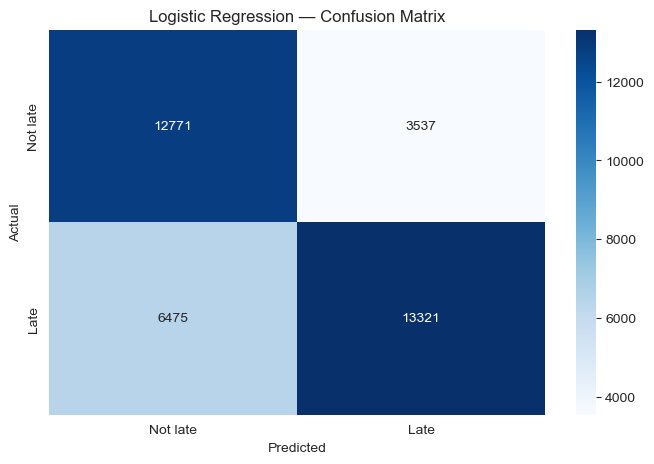

In [22]:
# Look at the confusion matrix to see what kind of mistakes the model makes
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not late', 'Late'], yticklabels=['Not late', 'Late'])
plt.title('Logistic Regression — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


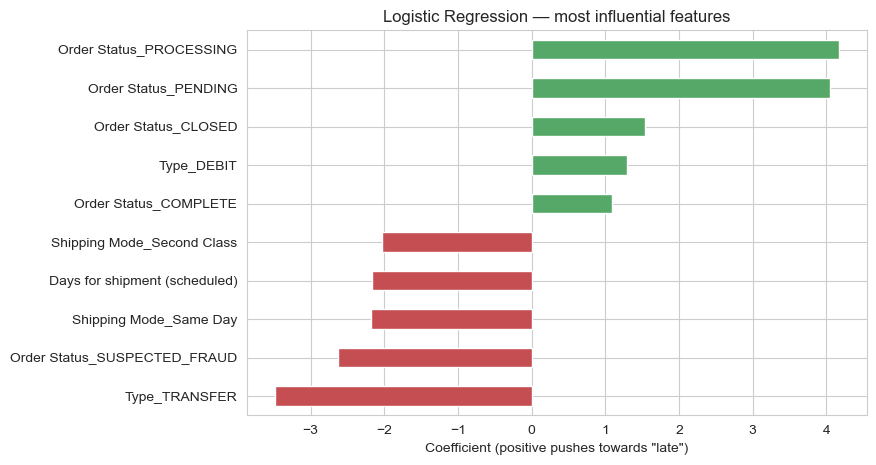

In [23]:
# Interpretability: the biggest positive/negative coefficients show which features
# push a prediction towards "late" or "not late"
coef_series = pd.Series(log_reg.coef_[0], index=X_train.columns).sort_values()
top_features = pd.concat([coef_series.head(5), coef_series.tail(5)])
top_features.plot(kind='barh', color=['#C44E52' if v < 0 else '#55A868' for v in top_features])
plt.title('Logistic Regression — most influential features')
plt.xlabel('Coefficient (positive pushes towards "late")')
plt.show()


### 5.2 Model 2 — Random Forest — (Pamindi M.M.)


In [24]:
# Train the Random Forest model
rand_forest = RandomForestClassifier(
    n_estimators=300, max_depth=18, min_samples_leaf=3,
    random_state=RANDOM_STATE, n_jobs=-1
)
rand_forest.fit(X_train, y_train)

# Predict on the test set
y_pred_rf = rand_forest.predict(X_test)
y_proba_rf = rand_forest.predict_proba(X_test)[:, 1]

# Evaluate
print('Random Forest Results')
print('Accuracy :', accuracy_score(y_test, y_pred_rf))
print('Precision:', precision_score(y_test, y_pred_rf))
print('Recall   :', recall_score(y_test, y_pred_rf))
print('F1 score :', f1_score(y_test, y_pred_rf))
print('ROC AUC  :', roc_auc_score(y_test, y_proba_rf))


Random Forest Results
Accuracy : 0.7600819853755817
Precision: 0.8435995556104184
Recall   : 0.690442513639119
F1 score : 0.7593755208622701
ROC AUC  : 0.8539678611957244


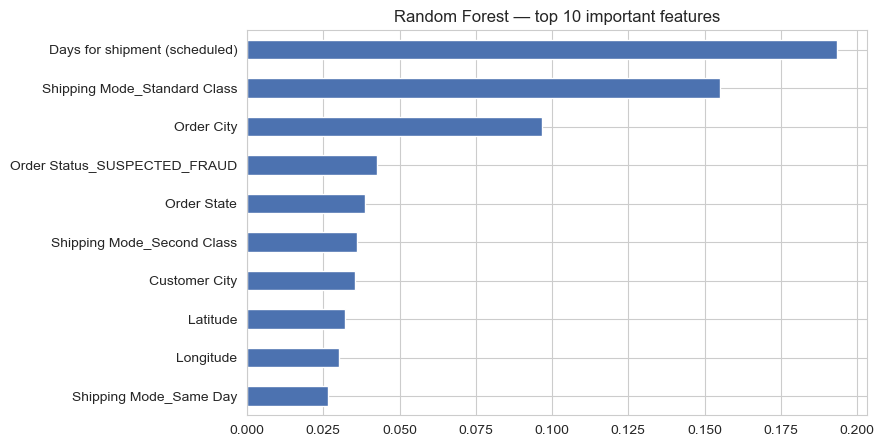

In [25]:
# Feature importance: which features the Random Forest relied on the most
importances = pd.Series(rand_forest.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=False).head(10).plot(kind='barh', color='#4C72B0')
plt.title('Random Forest — top 10 important features')
plt.gca().invert_yaxis()
plt.show()


### 5.3 Model 3 — Decision Tree — (Gunathunga K.S.N.T.)


In [26]:
# Train the Decision Tree model
# max_depth and min_samples_leaf are set to reasonable values to avoid the tree
# memorising the training data (overfitting)
dec_tree = DecisionTreeClassifier(
    max_depth=16, min_samples_leaf=8, random_state=RANDOM_STATE
)
dec_tree.fit(X_train, y_train)

# Predict on the test set
y_pred_dt = dec_tree.predict(X_test)
y_proba_dt = dec_tree.predict_proba(X_test)[:, 1]

# Evaluate
print('Decision Tree Results')
print('Accuracy :', accuracy_score(y_test, y_pred_dt))
print('Precision:', precision_score(y_test, y_pred_dt))
print('Recall   :', recall_score(y_test, y_pred_dt))
print('F1 score :', f1_score(y_test, y_pred_dt))
print('ROC AUC  :', roc_auc_score(y_test, y_proba_dt))


Decision Tree Results
Accuracy : 0.7644305340128518
Precision: 0.8208946740180754
Recall   : 0.7295413214790867
F1 score : 0.7725266789697505
ROC AUC  : 0.8484600488757712


In [27]:
# Check the training accuracy too, to see how much the tree is overfitting
train_acc_dt = accuracy_score(y_train, dec_tree.predict(X_train))
test_acc_dt = accuracy_score(y_test, y_pred_dt)
print(f'Train accuracy: {train_acc_dt:.4f}')
print(f'Test accuracy : {test_acc_dt:.4f}')
print(f'Gap (overfitting check): {train_acc_dt - test_acc_dt:.4f}')


Train accuracy: 0.8068
Test accuracy : 0.7644
Gap (overfitting check): 0.0424


### 5.4 Model 4 — XGBoost — (Rathnamalala R.I.B.T.)


In [28]:
# Train the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=350, max_depth=7, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    random_state=RANDOM_STATE, eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

# Predict on the test set
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate
print('XGBoost Results')
print('Accuracy :', accuracy_score(y_test, y_pred_xgb))
print('Precision:', precision_score(y_test, y_pred_xgb))
print('Recall   :', recall_score(y_test, y_pred_xgb))
print('F1 score :', f1_score(y_test, y_pred_xgb))
print('ROC AUC  :', roc_auc_score(y_test, y_proba_xgb))


XGBoost Results
Accuracy : 0.7742078440062043
Precision: 0.8346746378477811
Recall   : 0.7334815114164478
F1 score : 0.7808130780813078
ROC AUC  : 0.8680719123011549


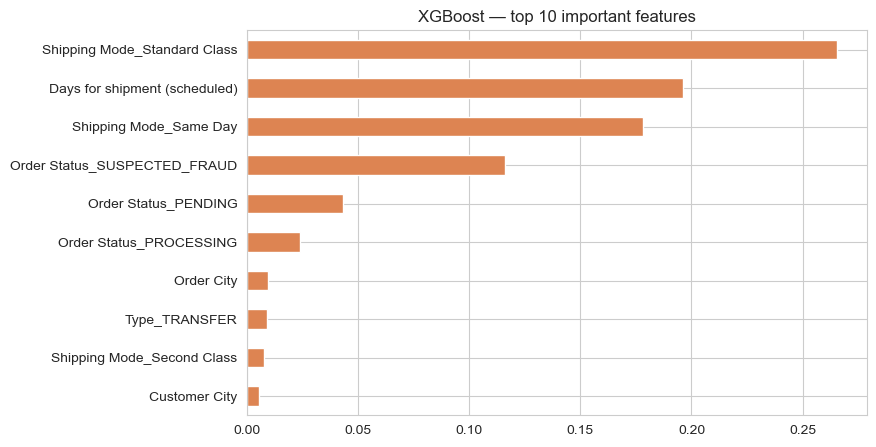

In [29]:
# Feature importance for XGBoost
xgb_importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
xgb_importances.sort_values(ascending=False).head(10).plot(kind='barh', color='#DD8452')
plt.title('XGBoost — top 10 important features')
plt.gca().invert_yaxis()
plt.show()



## 6. Validation, Model Comparison & Recommendation (Rathnamalala R.I.B.T.)

### 6.1 Cross-validation robustness check



In [30]:
# Take a stratified sample of the training data for the cross-validation check
sample_idx, _ = train_test_split(
    X_train.index, train_size=40000, random_state=RANDOM_STATE, stratify=y_train
)
X_cv = X_train.loc[sample_idx]
y_cv = y_train.loc[sample_idx]
X_cv_scaled = scaler.transform(X_cv)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

cv_scores = {
    'Logistic Regression': cross_val_score(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), X_cv_scaled, y_cv, cv=cv, scoring='accuracy'),
    'Decision Tree': cross_val_score(DecisionTreeClassifier(max_depth=16, min_samples_leaf=8, random_state=RANDOM_STATE), X_cv, y_cv, cv=cv, scoring='accuracy'),
    'Random Forest': cross_val_score(RandomForestClassifier(n_estimators=200, max_depth=18, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1), X_cv, y_cv, cv=cv, scoring='accuracy'),
    'XGBoost': cross_val_score(XGBClassifier(n_estimators=200, max_depth=7, learning_rate=0.1, random_state=RANDOM_STATE, eval_metric='logloss'), X_cv, y_cv, cv=cv, scoring='accuracy'),
}

for name, scores in cv_scores.items():
    print(f'{name}: mean accuracy = {scores.mean():.4f}, std = {scores.std():.4f}')


Logistic Regression: mean accuracy = 0.7378, std = 0.0022
Decision Tree: mean accuracy = 0.7043, std = 0.0048
Random Forest: mean accuracy = 0.7355, std = 0.0032
XGBoost: mean accuracy = 0.7401, std = 0.0026


### 6.2 Final model comparison

In [31]:
# Put all four models' test-set results together into one comparison table
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb),
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb),
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb),
    ],
    'ROC AUC': [
        roc_auc_score(y_test, y_proba_lr),
        roc_auc_score(y_test, y_proba_dt),
        roc_auc_score(y_test, y_proba_rf),
        roc_auc_score(y_test, y_proba_xgb),
    ],
})

comparison = comparison.round(4)
comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7227,0.7902,0.6729,0.7269,0.8028
1,Decision Tree,0.7644,0.8209,0.7295,0.7725,0.8485
2,Random Forest,0.7601,0.8436,0.6904,0.7594,0.8540
3,XGBoost,0.7742,0.8347,0.7335,0.7808,0.8681


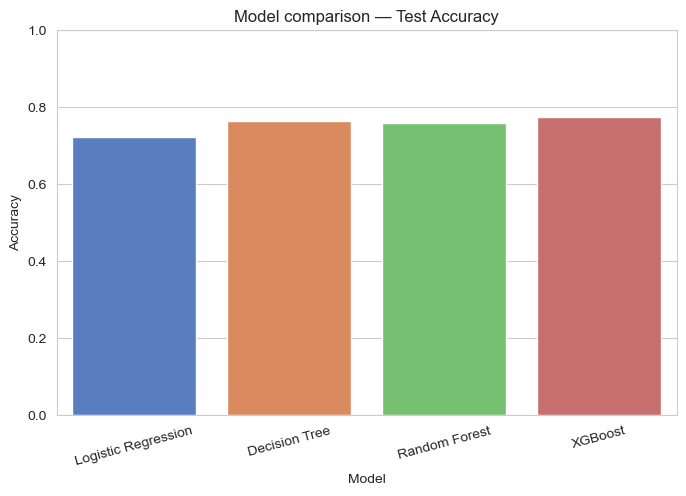

In [32]:
# Bar chart comparing accuracy across the four models
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison, x='Model', y='Accuracy', hue='Model', palette='muted', legend=False)
plt.title('Model comparison — Test Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()


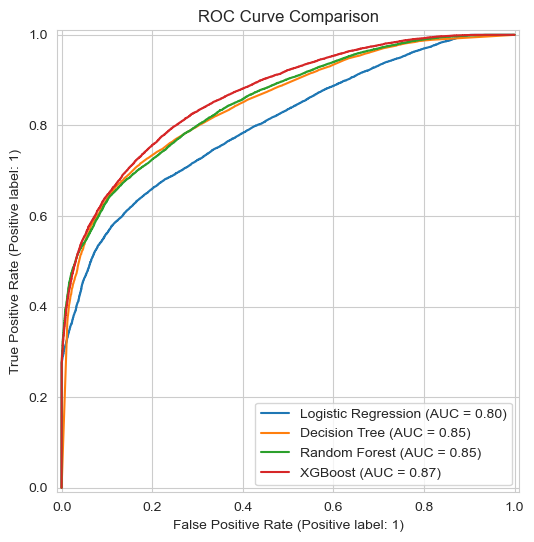

In [33]:
# ROC curves for all four models on the same plot
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name='Logistic Regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_dt, name='Decision Tree', ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_rf, name='Random Forest', ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_xgb, name='XGBoost', ax=ax)
plt.title('ROC Curve Comparison')
plt.show()
